# Tasks - Lab 3

## Task 3.1: Precursor Batching & Reaction Stoichiometry in Cathode Synthesis

In [42]:
# ==============================================================================
# TASK 3.1: PRECURSOR BATCHING IN CATHODE SYNTHESIS (STARTER TEMPLATE)
# ==============================================================================
import pandas as pd
from pymatgen.core import Composition
from pymatgen.analysis.reaction_calculator import Reaction

TARGET_MASS_G = 100.0  # Target product mass in grams

# ------------------------------------------------------------------------------
# STEP 1: DEFINE CHEMICAL COMPOSITIONS
# ------------------------------------------------------------------------------
# TODO: Instantiate target cathode product (NMC622)
target_nmc = Composition(
    {"Li": 1, "Ni": 0.6, "Mn": 0.2, "Co": 0.2, "O": 2}
)  # LiNi0.6Mn0.2Co0.2O2

# TODO: Define reactant compositions: Li2CO3, NiO, MnO2, Co3O4, O2
reactants = [
    Composition({"Li": 2, "C": 1, "O": 3}),  # Li2CO3
    Composition({"Ni": 1, "O": 1}),  # NiO
    Composition({"Mn": 1, "O": 2}),  # MnO2
    Composition({"Co": 3, "O": 4}),  # Co3O4
    Composition({"O": 2}),  # O2
]

# TODO: Define product compositions: target_nmc, CO2
products = [
    target_nmc,  # LiNi0.6Mn0.2Co0.2O2
    Composition({"C": 1, "O": 2}),  # CO2
]


# ------------------------------------------------------------------------------
# STEP 2: BALANCE & NORMALIZE SOLID-STATE REACTION
# ------------------------------------------------------------------------------
# TODO: Create the Reaction object
rxn = Reaction(reactants=reactants, products=products)

# TODO: Normalize the reaction with respect to target_nmc (target coefficient = 1.0)
rxn.normalize_to(comp=target_nmc, factor=1.0)

print("--- Balanced Calcination Reaction ---")
print(rxn)


# ------------------------------------------------------------------------------
# STEP 3: PRECURSOR MASS BATCHING CALCULATIONS
# ------------------------------------------------------------------------------
# TODO: Calculate molar mass and moles needed for 100.0 g of target_nmc
target_molar_mass = target_nmc.weight
n_target = TARGET_MASS_G / target_molar_mass

batch_records = []

# Solid precursors to measure on the scale
solid_precursors = ["Li2CO3", "NiO", "MnO2", "Co3O4"]

# TODO: Iterate over solid precursors, compute stoichiometric moles and mass in grams
for formula_str in solid_precursors:
    # Get the corresponding reactant composition
    reactant_comp = next(
        comp for comp in reactants if comp.reduced_formula == formula_str
    )

    # Get the stoichiometric coefficient from the reaction
    coeff = abs(rxn.get_coeff(reactant_comp))

    # Calculate moles needed based on target_nmc moles
    n_precursor = coeff * n_target

    # Calculate mass in grams
    mass_g = n_precursor * reactant_comp.weight

    # Store the results in batch_records
    batch_records.append(
        {
            "Precursor": formula_str,
            "Stoichiometric Coefficient": coeff,
            "Moles Needed (mol)": n_precursor,
            "Mass Needed (g)": mass_g,
        }
    )

df_batch = pd.DataFrame(batch_records)
print("\n--- Analytical Batching Recipe (Target: 100.0 g NMC622) ---")
print(df_batch.to_string(index=False, float_format="{:,.4f}".format, justify="center"))

--- Balanced Calcination Reaction ---
0.5 Li2CO3 + 0.6 NiO + 0.2 MnO2 + 0.06667 Co3O4 + 0.1167 O2 -> Li1Mn0.2Co0.2Ni0.6O2 + 0.5 CO2

--- Analytical Batching Recipe (Target: 100.0 g NMC622) ---
Precursor  Stoichiometric Coefficient  Moles Needed (mol)  Mass Needed (g)
  Li2CO3             0.5000                  0.5158           38.1156     
     NiO             0.6000                  0.6190           46.2351     
    MnO2             0.2000                  0.2063           17.9381     
   Co3O4             0.0667                  0.0688           16.5616     


## Task 3.2: Hume-Rothery Screening & Feature Engineering for High-Entropy Alloys (HEAs)


In [43]:
# ==============================================================================
# TASK 3.2: HUME-ROTHERY ALLOY SCREENING (STARTER TEMPLATE)
# ==============================================================================
import numpy as np
import pandas as pd
from pymatgen.core import Element, Composition

# ------------------------------------------------------------------------------
# STEP 1: DEFINE CANDIDATE ALLOY SYSTEMS
# ------------------------------------------------------------------------------
alloy_inputs = {
    "Cantor Alloy (Equiatomic)": "Fe20Co20Cr20Ni20Mn20",
    "Al-Doped Cantor": "Al10Fe22.5Co22.5Cr22.5Ni22.5",
    "Refractory BCC HEA": "Ti20Zr20Nb20Hf20Ta20",
    # Weight-percent input: 50% Al, 30% Mg, 20% Ti
    "Lightweight Al-Mg-Ti (wt%)": {"Al": 50.0, "Mg": 30.0, "Ti": 20.0},
    "BMG Glass Former": "Zr55Cu30Al10Ni5",
}

results = []

for name, spec in alloy_inputs.items():
    # TODO: Instantiate comp as a Composition object
    # Hint: Use Composition.from_weight_dict() if spec is a dict, else Composition(spec)
    comp = (
        Composition.from_weight_dict(spec)
        if isinstance(spec, dict)
        else Composition(spec)
    )

    # TODO: Normalize composition to fractional atom counts
    frac_comp = comp.fractional_composition

    # TODO: Extract elements and their atomic fractions into NumPy arrays
    elements = np.array(list(frac_comp.keys()))
    x_i = np.array(list(frac_comp.values()))

    # TODO: Extract atomic radii (r_i) and Pauling electronegativities (chi_i)
    # Remember to cast each property to float()
    r_i = np.array([float(Element(el).atomic_radius) for el in elements])  # type: ignore[arg-type]
    chi_i = np.array([float(Element(el).X) for el in elements])

    # TODO: Compute weighted mean radius (r_bar) and mean electronegativity (chi_bar)
    r_bar = np.sum(x_i * r_i)
    chi_bar = np.sum(x_i * chi_i)

    # TODO: Compute Hume-Rothery mismatch delta_r (%) and electronegativity mismatch delta_chi
    delta_r = np.sqrt(np.sum(x_i * ((r_i - r_bar) / r_bar) ** 2)) * 100
    delta_chi = np.sqrt(np.sum(x_i * (chi_i - chi_bar) ** 2))

    # TODO: Apply classification rule based on delta_r thresholds (6.6% and 15.0%)
    classification = (
        "Favorable for Solid Solution"
        if delta_r < 6.6
        else "Likely Intermetallic or Phase Separation"
        if delta_r > 15.0
        else "Intermediate Behavior"
    )

    # Append results dictionary
    results.append(
        {
            "Alloy System": name,
            "Composition (at.%)": " ".join(
                f"{el}{x * 100:.1f}" for el, x in zip(elements, x_i)
            ),
            "r̄ (Å)": r_bar,
            "χ̄": chi_bar,
            "δr (%)": delta_r,
            "δχ": delta_chi,
            "Classification": classification,
        }
    )

df_hea = pd.DataFrame(results)

# The output was a bit messy, so I added some formatting to make it more readable :)
text_cols = ["Alloy System", "Composition (at.%)", "Classification"]
formatters = {
    col: (lambda s, w=df_hea[col].str.len().max(): f"{s:<{w}}") for col in text_cols
}

print("\n--- Hume-Rothery Screening of Candidate Alloys ---")
print(
    df_hea.to_string(
        index=False, float_format="{:.3f}".format, formatters=formatters, justify="left"
    )
)


--- Hume-Rothery Screening of Candidate Alloys ---
Alloy System               Composition (at.%)                  r̄ (Å)  χ̄    δr (%)  δχ   Classification              
Cantor Alloy (Equiatomic)  Fe20.0 Co20.0 Cr20.0 Ni20.0 Mn20.0 1.380   1.766 1.775   0.138 Favorable for Solid Solution
Al-Doped Cantor            Al10.0 Fe22.5 Co22.5 Cr22.5 Ni22.5 1.363   1.799 3.257   0.111 Favorable for Solid Solution
Refractory BCC HEA         Ti20.0 Zr20.0 Nb20.0 Hf20.0 Ta20.0 1.480   1.454 4.054   0.118 Favorable for Solid Solution
Lightweight Al-Mg-Ti (wt%) Al52.9 Mg35.2 Ti11.9               1.356   1.496 8.560   0.139 Intermediate Behavior       
BMG Glass Former           Zr55.0 Cu30.0 Al10.0 Ni5.0         1.450   1.558 7.863   0.265 Intermediate Behavior       


## Task 3.3: Crystal Electroneutrality & Mixed-Valence Tracking in Defect Oxides


--- Non-Stoichiometric Wüstite (Fe_(1-x)O) Defect Table ---
    x  Fe2+  Fe3+  Total Fe  Fe3+ (%)  r_cat (Å)
0.020 0.940 0.040     0.980     4.082      0.914
0.030 0.910 0.060     0.970     6.186      0.912
0.040 0.880 0.080     0.960     8.333      0.909
0.050 0.850 0.100     0.950    10.526      0.906
0.060 0.820 0.120     0.940    12.766      0.903
0.070 0.790 0.140     0.930    15.054      0.900
0.080 0.760 0.160     0.920    17.391      0.897
0.090 0.730 0.180     0.910    19.780      0.893
0.100 0.700 0.200     0.900    22.222      0.890
0.110 0.670 0.220     0.890    24.719      0.887
0.120 0.640 0.240     0.880    27.273      0.883
0.130 0.610 0.260     0.870    29.885      0.880
0.140 0.580 0.280     0.860    32.558      0.876


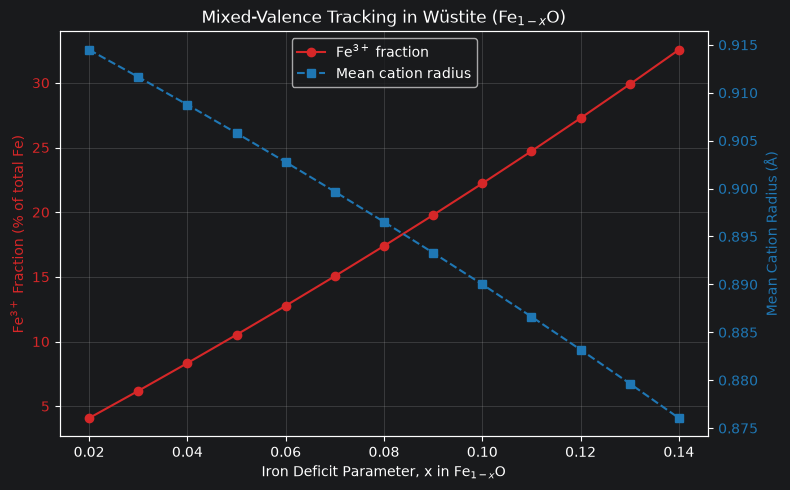

In [44]:
# ==============================================================================
# TASK 3.3: DEFECT EQUILIBRIA & ELECTRONEUTRALITY (STARTER TEMPLATE)
# ==============================================================================
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.core import Species, Composition

# Composition.charge is flagged as experimental by pymatgen; silence only that warning
warnings.filterwarnings("ignore", message="Composition.charge is experimental")


# ------------------------------------------------------------------------------
# STEP 1: DEFINE DEFECT COMPOSITION BUILDER FUNCTION
# ------------------------------------------------------------------------------
def build_wustite_composition(x: float) -> Composition:
    """
    Constructs a charge-neutral Composition object for Fe_(1-x)O
    using explicit Species instances.
    """
    # TODO: Calculate mole amounts of Fe2+, Fe3+, and O2- based on defect balance
    n_fe3 = 2.0 * x
    n_fe2 = 1.0 - 3.0 * x
    n_o2 = 1.0

    # TODO: Create a Composition mapping Species to stoichiometric amounts
    # Hint: Species("Fe", 2), Species("Fe", 3), Species("O", -2)
    comp = Composition(
        {
            Species("Fe", 2): n_fe2,
            Species("Fe", 3): n_fe3,
            Species("O", -2): n_o2,
        }
    )

    # TODO: Verify crystal electroneutrality via comp.charge
    charge = float(comp.charge)  # type: ignore[arg-type]
    assert abs(charge) < 1e-6, f"Charge neutrality violated: {charge}"

    return comp


# ------------------------------------------------------------------------------
# STEP 2: PARAMETRIC SWEEP OVER VACANCY DEFECT RANGE x in [0.02, 0.14]
# ------------------------------------------------------------------------------
x_values = np.linspace(0.02, 0.14, 13)

# Query ionic radii for iron species (cast to float)
r_fe2 = float(Species("Fe", 2).ionic_radius)  # type: ignore[arg-type]
r_fe3 = float(Species("Fe", 3).ionic_radius)  # type: ignore[arg-type]

defect_records = []

for x in x_values:
    # TODO: Build composition for current x
    comp = build_wustite_composition(x)

    # TODO: Extract molar amounts of Fe2+, Fe3+, and total iron
    n_fe2 = comp.get(Species("Fe", 2), 0.0)
    n_fe3 = comp.get(Species("Fe", 3), 0.0)
    n_fe_total = n_fe2 + n_fe3

    # TODO: Calculate ferric percentage (% Fe3+) and mean cation radius
    fe3_pct = (n_fe3 / n_fe_total) * 100 if n_fe_total > 0 else 0.0
    r_cation_avg = (
        (n_fe2 * r_fe2 + n_fe3 * r_fe3) / n_fe_total if n_fe_total > 0 else 0.0
    )

    defect_records.append(
        {
            "x": x,
            "Fe2+": n_fe2,
            "Fe3+": n_fe3,
            "Total Fe": n_fe_total,
            "Fe3+ (%)": fe3_pct,
            "r_cat (Å)": r_cation_avg,
        }
    )

df_defect = pd.DataFrame(defect_records)
print("--- Non-Stoichiometric Wüstite (Fe_(1-x)O) Defect Table ---")
print(df_defect.to_string(index=False, float_format="{:.3f}".format))


# ------------------------------------------------------------------------------
# STEP 3: DUAL-AXIS VISUALIZATION OF DEFECT CONCENTRATION TRENDS
# ------------------------------------------------------------------------------
# TODO: Create a dual-axis plot showing:
#   Left y-axis : Fe3+ fraction (% of total Fe)
#   Right y-axis: Mean Cation Radius (Å)
#   x-axis      : Iron Deficit Parameter (x in Fe_(1-x)O)
fig, ax_left = plt.subplots(figsize=(8, 5))

color_fe3 = "tab:red"
color_r = "tab:blue"

ax_left.plot(
    df_defect["x"],
    df_defect["Fe3+ (%)"],
    color=color_fe3,
    marker="o",
    label="Fe$^{3+}$ fraction",
)
ax_left.set_xlabel("Iron Deficit Parameter, x in Fe$_{1-x}$O")
ax_left.set_ylabel("Fe$^{3+}$ Fraction (% of total Fe)", color=color_fe3)
ax_left.tick_params(axis="y", labelcolor=color_fe3)
ax_left.grid(alpha=0.3)

ax_right = ax_left.twinx()
ax_right.plot(
    df_defect["x"],
    df_defect["r_cat (Å)"],
    color=color_r,
    marker="s",
    linestyle="--",
    label="Mean cation radius",
)
ax_right.set_ylabel("Mean Cation Radius (Å)", color=color_r)
ax_right.tick_params(axis="y", labelcolor=color_r)

# Combine legends from both axes
lines = ax_left.get_legend_handles_labels()
lines_r = ax_right.get_legend_handles_labels()
ax_left.legend(lines[0] + lines_r[0], lines[1] + lines_r[1], loc="upper center")

ax_left.set_title("Mixed-Valence Tracking in Wüstite (Fe$_{1-x}$O)")
fig.tight_layout()
plt.show()